<a href="https://colab.research.google.com/github/MikhailMikheev17/123/blob/master/%D0%94%D0%B5%D1%80%D0%B5%D0%B2%D0%BE_%D0%9F%D0%A0%D0%BE%D0%B1%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Создание нового набора данных уже со столбцами.

In [1]:
import pandas as pd

# Новые имена столбцов
column_names = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
                "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
                "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
                "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
                "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
                "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
                "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
                "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
                "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
                "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "class"]

# Загрузка CSV-файла без заголовков
input_file = 'kddcupdatacorrected.csv'
df = pd.read_csv(input_file, header=None)

# Присвоение новых имен столбцам
df.columns = column_names

# Сохранение CSV-файла с новыми заголовками
output_file = 'kdd1.csv'
df.to_csv(output_file, index=False)

# Просмотр первых строк для проверки
print(df.head())

   duration protocol_type service flag  src_bytes  dst_bytes  land  \
0         0           tcp    http   SF        215      45076     0   
1         0           tcp    http   SF        162       4528     0   
2         0           tcp    http   SF        236       1228     0   
3         0           tcp    http   SF        233       2032     0   
4         0           tcp    http   SF        239        486     0   

   wrong_fragment  urgent  hot  ...  dst_host_srv_count  \
0               0       0    0  ...                   0   
1               0       0    0  ...                   1   
2               0       0    0  ...                   2   
3               0       0    0  ...                   3   
4               0       0    0  ...                   4   

   dst_host_same_srv_rate  dst_host_diff_srv_rate  \
0                     0.0                     0.0   
1                     1.0                     0.0   
2                     1.0                     0.0   
3           

Преобразование всех параметров в цифру.

In [2]:
for col in df.select_dtypes(include=["object"]):
    print(col)

protocol_type
service
flag
class


In [8]:
from sklearn.preprocessing import LabelEncoder

cols = ['protocol_type','service','flag','class']

for i in cols:
    en = LabelEncoder()

    df[i] = en.fit_transform(df[i])

df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,1,24,9,215,45076,0,0,0,0,...,0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,11
1,0,1,24,9,162,4528,0,0,0,0,...,1,1.0,0.0,1.00,0.0,0.0,0.0,0.0,0.0,11
2,0,1,24,9,236,1228,0,0,0,0,...,2,1.0,0.0,0.50,0.0,0.0,0.0,0.0,0.0,11
3,0,1,24,9,233,2032,0,0,0,0,...,3,1.0,0.0,0.33,0.0,0.0,0.0,0.0,0.0,11
4,0,1,24,9,239,486,0,0,0,0,...,4,1.0,0.0,0.25,0.0,0.0,0.0,0.0,0.0,11


In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Загрузка данных
def load_data(file_path):
    column_names = ["duration","protocol_type","service","flag","src_bytes",
    "dst_bytes","land","wrong_fragment","urgent","hot","num_failed_logins",
    "logged_in","num_compromised","root_shell","su_attempted","num_root",
    "num_file_creations","num_shells","num_access_files","num_outbound_cmds",
    "is_host_login","is_guest_login","count","srv_count","serror_rate",
    "srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate",
    "diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count",
    "dst_host_same_srv_rate","dst_host_diff_srv_rate","dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate",
    "dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty_level"]

    df = pd.read_csv(file_path, header=None, names=column_names)
    return df

# Предобработка данных
def preprocess_data(df):
    # Удаление столбца difficulty_level
    df = df.drop('difficulty_level', axis=1)

    # Кодирование категориальных признаков
    le = LabelEncoder()
    categorical_columns = ['protocol_type', 'service', 'flag']
    for column in categorical_columns:
        df[column] = le.fit_transform(df[column])

    # Преобразование меток в бинарный формат (0 - нормальный, 1 - аномальный)
    df['label'] = df['label'].apply(lambda x: 0 if x == 'normal' else 1)

    # Разделение на признаки и метки
    X = df.drop('label', axis=1)
    y = df['label']

    return X, y

# Основная функция
def main():
    # Загрузка данных
    df = load_data('kddcupdatacorrected.csv')

    # Предобработка данных
    X, y = preprocess_data(df)

    # Разделение на обучающий и тестовый наборы
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Создание и обучение модели Decision Tree
    dt_classifier = DecisionTreeClassifier(random_state=42)
    dt_classifier.fit(X_train, y_train)

    # Предсказания
    y_pred = dt_classifier.predict(X_test)

    # Оценка модели
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {accuracy:.4f}")

    # Вывод отчета о классификации
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=['Normal', 'Anomaly']))

    # Вывод матрицы ошибок
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    # Визуализация дерева решений (первые 3 уровня)
    plt.figure(figsize=(20,10))
    plot_tree(dt_classifier, max_depth=3, feature_names=X.columns,
              class_names=['Normal', 'Anomaly'], filled=True, rounded=True)
    plt.savefig('decision_tree.png', dpi=300, bbox_inches='tight')
    print("\nDecision tree visualization saved as 'decision_tree.png'")

    # Важность признаков
    feature_importance = pd.DataFrame({'feature': X.columns, 'importance': dt_classifier.feature_importances_})
    feature_importance = feature_importance.sort_values('importance', ascending=False).head(10)
    print("\nTop 10 Important Features:")
    print(feature_importance)

if __name__ == "__main__":
    main()

Accuracy: 1.0000

Classification Report:


ValueError: Number of classes, 1, does not match size of target_names, 2. Try specifying the labels parameter

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Загрузка данных
def load_data(file_path):
    column_names = ["duration","protocol_type","service","flag","src_bytes",
    "dst_bytes","land","wrong_fragment","urgent","hot","num_failed_logins",
    "logged_in","num_compromised","root_shell","su_attempted","num_root",
    "num_file_creations","num_shells","num_access_files","num_outbound_cmds",
    "is_host_login","is_guest_login","count","srv_count","serror_rate",
    "srv_serror_rate","rerror_rate","srv_rerror_rate","same_srv_rate",
    "diff_srv_rate","srv_diff_host_rate","dst_host_count","dst_host_srv_count",
    "dst_host_same_srv_rate","dst_host_diff_srv_rate","dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate","dst_host_serror_rate","dst_host_srv_serror_rate",
    "dst_host_rerror_rate","dst_host_srv_rerror_rate","label","difficulty_level"]

    df = pd.read_csv(file_path, header=None, names=column_names)
    return df

# Предобработка данных
def preprocess_data(df):
    # Удаление столбца difficulty_level
    df = df.drop('difficulty_level', axis=1)

    # Кодирование категориальных признаков
    le = LabelEncoder()
    categorical_columns = ['protocol_type', 'service', 'flag', 'label']
    for column in categorical_columns:
        df[column] = le.fit_transform(df[column])

    # Разделение на признаки и метки
    X = df.drop('label', axis=1)
    y = df['label']

    return X, y

# Основная функция
def main():
    # Загрузка данных
    df = load_data('kddcupdatacorrected.csv')

    # Предобработка данных
    X, y = preprocess_data(df)

    # Разделение на обучающий и тестовый наборы
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Создание и обучение модели Decision Tree
    dt_classifier = DecisionTreeClassifier(random_state=42)
    dt_classifier.fit(X_train, y_train)

    # Предсказания
    y_pred = dt_classifier.predict(X_test)

    # Оценка модели
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Accuracy: {accuracy:.4f}")

    # Вывод отчета о классификации
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # Вывод матрицы ошибок
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    # Визуализация дерева решений (первые 3 уровня)
    plt.figure(figsize=(20,10))
    plot_tree(dt_classifier, max_depth=3, feature_names=X.columns,
              class_names=le.classes_, filled=True, rounded=True)
    plt.savefig('decision_tree.png', dpi=300, bbox_inches='tight')
    print("\nDecision tree visualization saved as 'decision_tree.png'")

    # Важность признаков
    feature_importance = pd.DataFrame({'feature': X.columns, 'importance': dt_classifier.feature_importances_})
    feature_importance = feature_importance.sort_values('importance', ascending=False).head(10)
    print("\nTop 10 Important Features:")
    print(feature_importance)

if __name__ == "__main__":
    main()

Accuracy: 0.9999

Classification Report:


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       468
           1       0.80      0.57      0.67         7
           2       1.00      0.25      0.40         4
           3       0.82      0.90      0.86        10
           4       0.00      0.00      0.00         1
           5       1.00      1.00      1.00      2515
           6       0.88      0.78      0.82         9
           7       0.33      0.50      0.40         2
           8       0.00      0.00      0.00         0
           9       1.00      1.00      1.00    214345
          10       1.00      0.99      0.99       505
          11       1.00      1.00      1.00    194689
          12       1.00      1.00      1.00         1
          13       1.00      1.00      1.00         1
          14       1.00      0.97      0.99        40
          15       1.00      1.00      1.00      2043
          16       0.33      0.50      0.40         2
          17       1.00    

NameError: name 'le' is not defined

<Figure size 2000x1000 with 0 Axes>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Загрузка данных
def load_data(file_path):
    df = pd.read_csv("kdd1.csv")
    return df

# Предобработка данных
def preprocess_data(df):
    # Кодирование категориальных признаков
    le = LabelEncoder()
    for column in df.select_dtypes(include=['object']).columns:
        df[column] = le.fit_transform(df[column])

    # Разделение на признаки и метки
    X = df.drop(['class'], axis=1)
    y = df['class']

    # Нормализация признаков
    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    return X, y

# Основная функция
def main():
    # Загрузка данных
    df = load_data('kdd1.csv')

    # Предобработка данных
    X, y = preprocess_data(df)

    # Разделение на обучающий и тестовый наборы
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Создание и обучение модели Decision Tree
    dt_classifier = DecisionTreeClassifier(random_state=42)
    dt_classifier.fit(X_train, y_train)

    # Оценка модели
    accuracy = dt_classifier.score(X_test, y_test)
    print(f"Test accuracy: {accuracy:.4f}")

    # Предсказания
    y_pred = dt_classifier.predict(X_test)

    # Вывод отчета о классификации
    print(classification_report(y_test, y_pred))

    # Вывод матрицы ошибок
    print(confusion_matrix(y_test, y_pred))



if __name__ == "__main__":
    main()

Корреляция

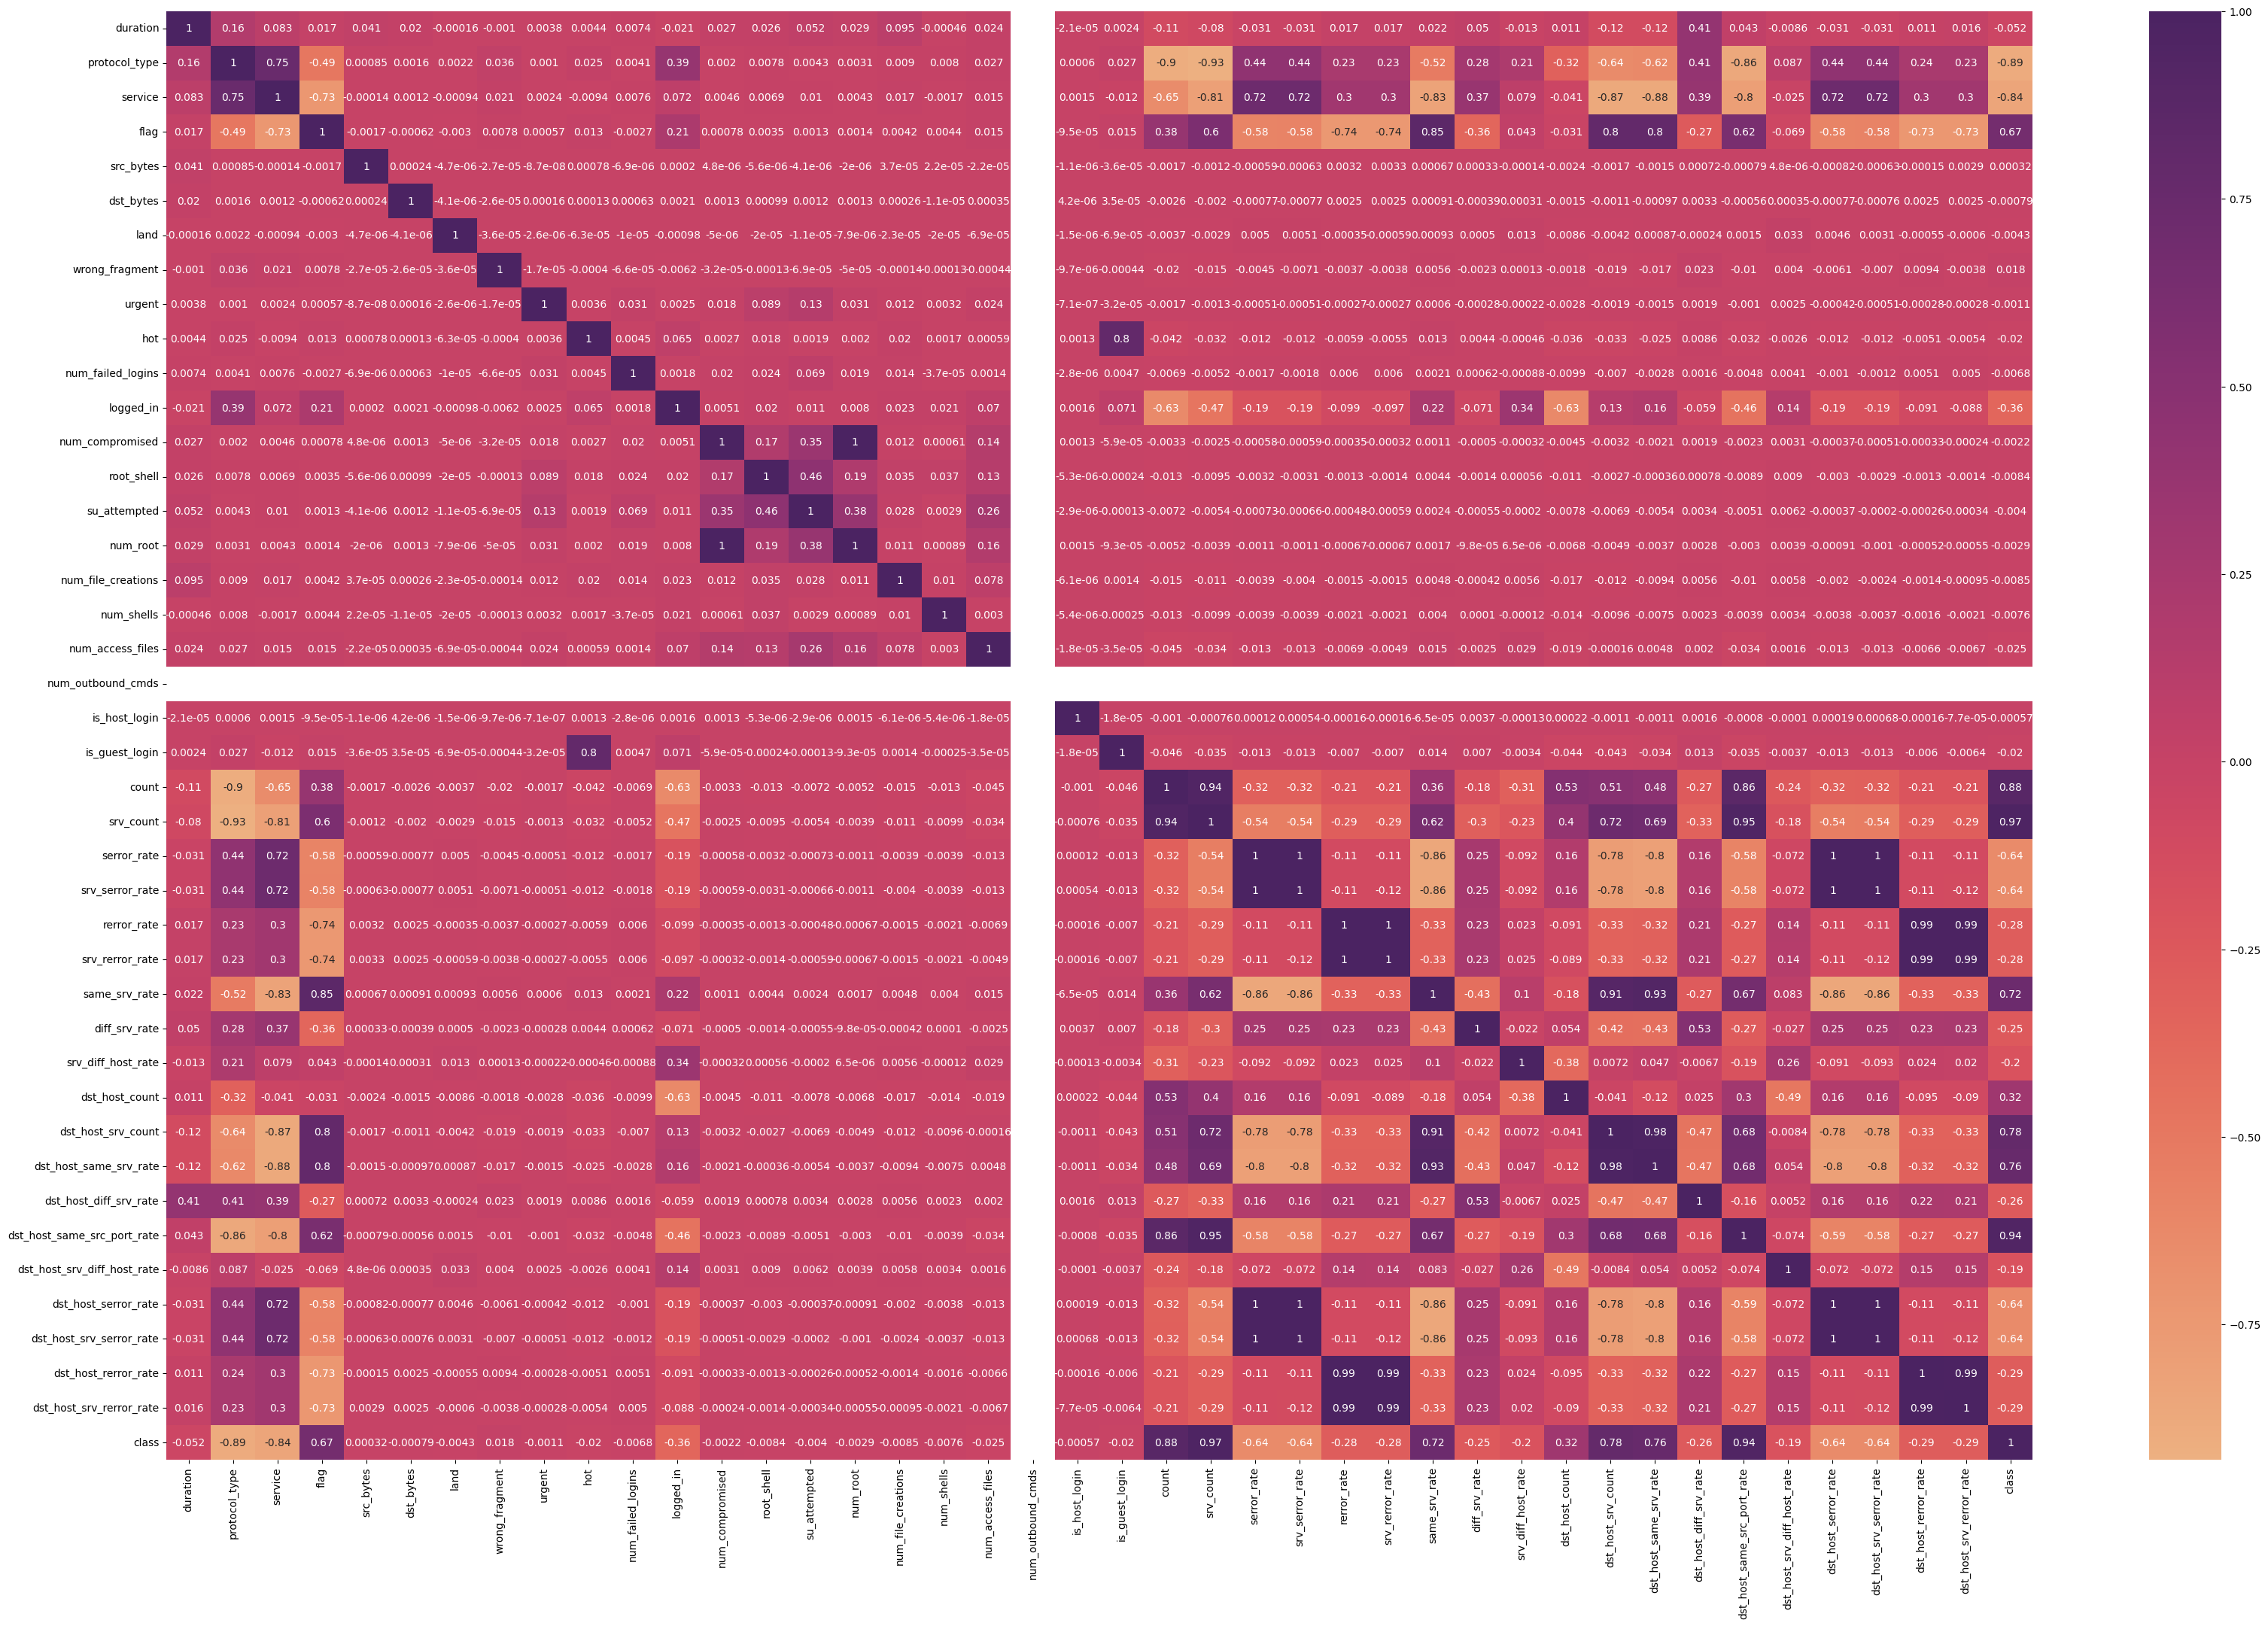

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

plt.figure(figsize=(40,25))
sns.heatmap(df.corr(),annot= True,cmap = 'flare')
plt.show()

In [10]:
corr_matrix = df.corr().abs()
corr_matrix

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
duration,1.000000,0.162993,0.083205,0.017171,4.122055e-02,0.020392,0.000160,0.001012,3.765465e-03,0.004450,...,0.117309,0.119105,0.409009,0.042774,0.008582,0.030546,0.030570,0.010569,0.016034,0.051923
protocol_type,0.162993,1.000000,0.748352,0.486096,8.452252e-04,0.001605,0.002250,0.036378,1.038418e-03,0.024957,...,0.640190,0.621542,0.409433,0.864810,0.087204,0.438943,0.438008,0.237346,0.234913,0.888373
service,0.083205,0.748352,1.000000,0.731090,1.398539e-04,0.001225,0.000938,0.021341,2.431153e-03,0.009432,...,0.872451,0.875266,0.389147,0.800890,0.024503,0.718908,0.717915,0.304244,0.303935,0.842976
flag,0.017171,0.486096,0.731090,1.000000,1.658673e-03,0.000615,0.003003,0.007820,5.700103e-04,0.013214,...,0.797973,0.803363,0.266634,0.616295,0.069295,0.584098,0.582495,0.728830,0.727751,0.666173
src_bytes,0.041221,0.000845,0.000140,0.001659,1.000000e+00,0.000239,0.000005,0.000027,8.677487e-08,0.000782,...,0.001715,0.001548,0.000719,0.000793,0.000005,0.000821,0.000635,0.000154,0.002927,0.000315
dst_bytes,0.020392,0.001605,0.001225,0.000615,2.393376e-04,1.000000,0.000004,0.000026,1.645208e-04,0.000126,...,0.001067,0.000968,0.003307,0.000558,0.000346,0.000765,0.000763,0.002502,0.002512,0.000789
land,0.000160,0.002250,0.000938,0.003003,4.659182e-06,0.000004,1.000000,0.000036,2.638263e-06,0.000063,...,0.004174,0.000865,0.000236,0.001479,0.033193,0.004648,0.003096,0.000552,0.000597,0.004326
wrong_fragment,0.001012,0.036378,0.021341,0.007820,2.714937e-05,0.000026,0.000036,1.000000,1.670585e-05,0.000402,...,0.018699,0.017398,0.022974,0.010194,0.003998,0.006090,0.007047,0.009444,0.003779,0.018388
urgent,0.003765,0.001038,0.002431,0.000570,8.677487e-08,0.000165,0.000003,0.000017,1.000000e+00,0.003591,...,0.001897,0.001549,0.001864,0.001047,0.002508,0.000420,0.000514,0.000277,0.000275,0.001129
hot,0.004450,0.024957,0.009432,0.013214,7.822053e-04,0.000126,0.000063,0.000402,3.590666e-03,1.000000,...,0.033378,0.025424,0.008587,0.031651,0.002604,0.011951,0.012134,0.005112,0.005434,0.019846


In [16]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

In [17]:
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]
to_drop

['num_root',
 'srv_serror_rate',
 'srv_rerror_rate',
 'dst_host_same_srv_rate',
 'dst_host_serror_rate',
 'dst_host_srv_serror_rate',
 'dst_host_rerror_rate',
 'dst_host_srv_rerror_rate',
 'class']

In [21]:
X_trn = df.drop(['labels'] , axis = 1).values
Y_trn = df['class'].values

KeyError: "['labels'] not found in axis"